# Medical Insurance Charges Prediction with Multi-Layer Perceptrons

This notebook predicts individual medical insurance charges from demographic and lifestyle features
(age, sex, BMI, number of children, smoking status, region) using fully connected neural networks
implemented in PyTorch.

**Pipeline:** exploratory data analysis → outlier analysis → Box-Cox / log transforms →
one-hot encoding and standardisation → comparison of six MLP architectures → evaluation in the
original dollar scale.

**Author:** Kiana Hashemi

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from scipy import stats
import torch
import torch.nn as nn
import torch.optim as optim

In [2]:
import json
import os
import random
from pathlib import Path

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Paths are relative to the notebooks/ directory and can be overridden with environment variables.
DATA_PATH = Path(os.environ.get("INSURANCE_DATA_PATH", "../data/insurance.csv"))
OUTPUT_DIR = Path(os.environ.get("OUTPUT_DIR", "../outputs"))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
EPOCHS = 2000  # full-batch training: one optimiser step per epoch
LEARNING_RATE = 0.001


def set_seed(seed=SEED):
    """Make weight initialisation and dropout reproducible."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()
print("Data file:", DATA_PATH.resolve())
print("PyTorch:", torch.__version__)

Data file: /repo/data/insurance.csv
PyTorch: 2.5.1


In [3]:
# Load the dataset
insurance_data = pd.read_csv(DATA_PATH)

# Display the first few rows of the dataset and some basic statistics
insurance_data.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [4]:
insurance_data.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [5]:
insurance_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


## Dataset Overview

The dataset comprises 1338 records, with the following features to predict health insurance charges based on several personal factors:

### Features
- **age**: Age of the primary beneficiary. (Numeric)
- **sex**: Gender of the insurance holder, either 'male' or 'female'. (Categorical)
- **bmi**: Body mass index, which correlates weight with height. (Numeric)
- **children**: Number of dependents covered by the health insurance. (Numeric)
- **smoker**: Indicates whether the individual smokes, with possible values 'yes' or 'no'. (Categorical)
- **region**: The residential region of the policyholder in the US, which can be 'northeast', 'southeast', 'southwest', or 'northwest'. (Categorical)
- **charges**: The actual medical costs billed by the health insurance. This is our target variable. (Numeric)

### Data Characteristics
- There are no missing values in the dataset, ensuring robustness in modeling.
- The dataset includes a mix of categorical and numerical features.
- Descriptive Statistics
From `insurance_data.describe()`, we observed that:
- The `age` feature ranges from 18 to 64 years, suggesting a good mix of young to elderly beneficiaries.
- The average BMI is around 30.66, which is slightly above the normal range, indicating a prevalence of overweight conditions among the beneficiaries.
- The `charges` vary widely, as shown by its high standard deviation, which points towards significant variability in medical costs.

### Preprocessing Requirements
For effective model training:
1. **Categorical variables** (`sex`, `smoker`, `region`) must be encoded into numerical form using techniques like one-hot encoding.
2. **Continuous variables** (`age`, `bmi`, `children`, `charges`) should be scaled or normalized to prevent any single feature from disproportionately affecting the model's learning.

## Data Preprocessing

In [6]:
# Step 1: Checking for Missing Values

missing_data = insurance_data.isnull().sum()
missing_data

#As confirmed, there are no missing values in any column of the dataset.

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

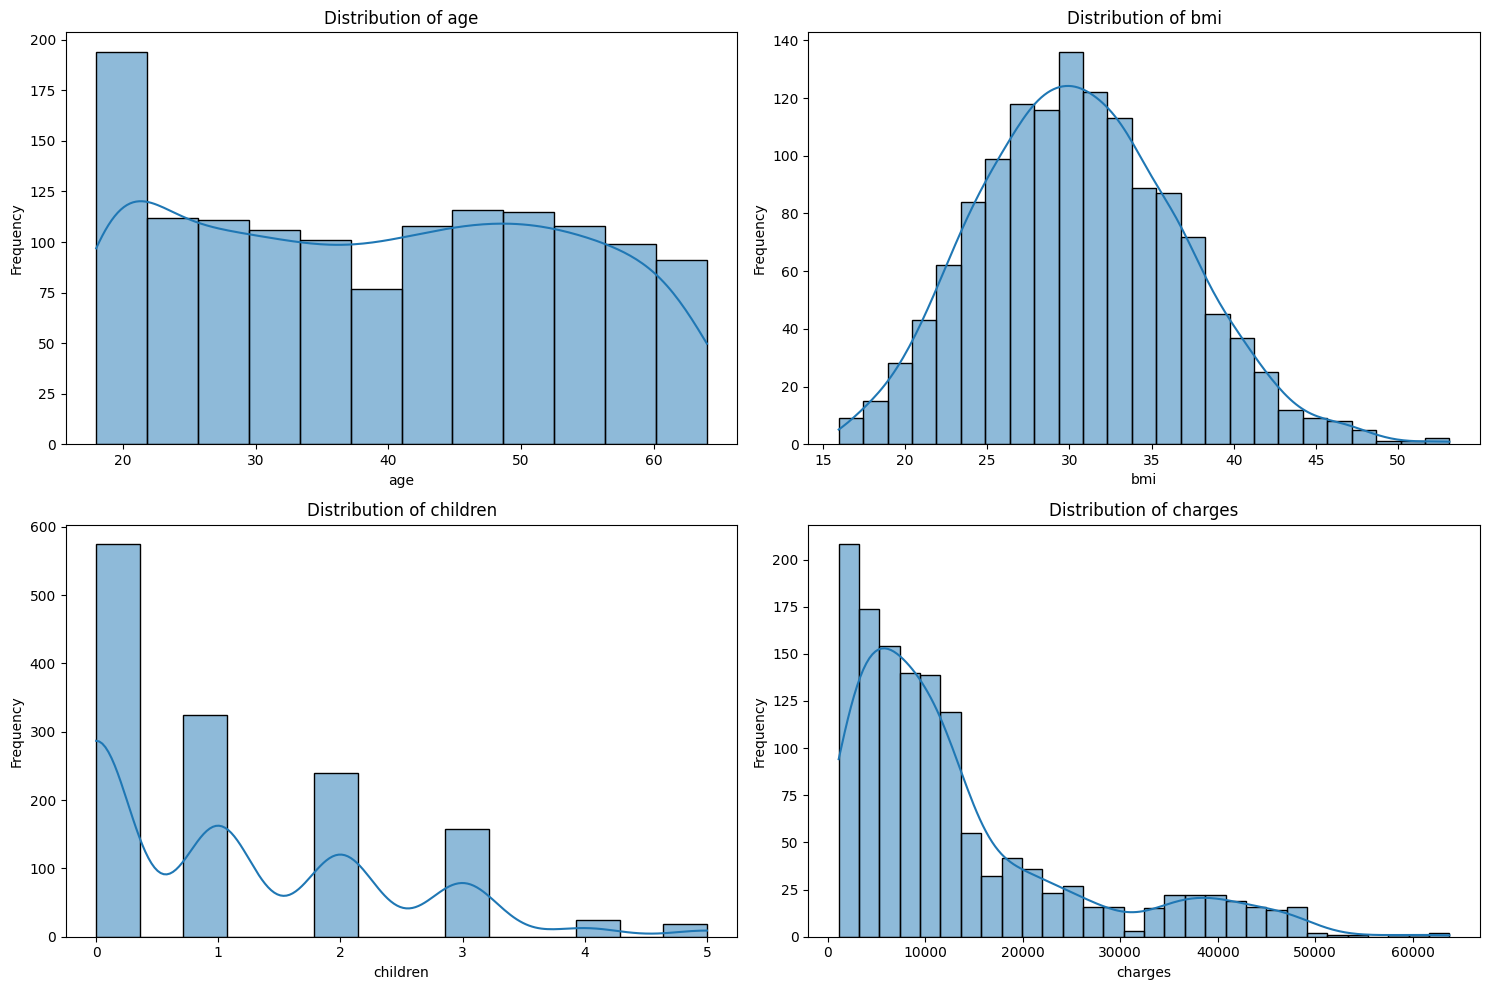

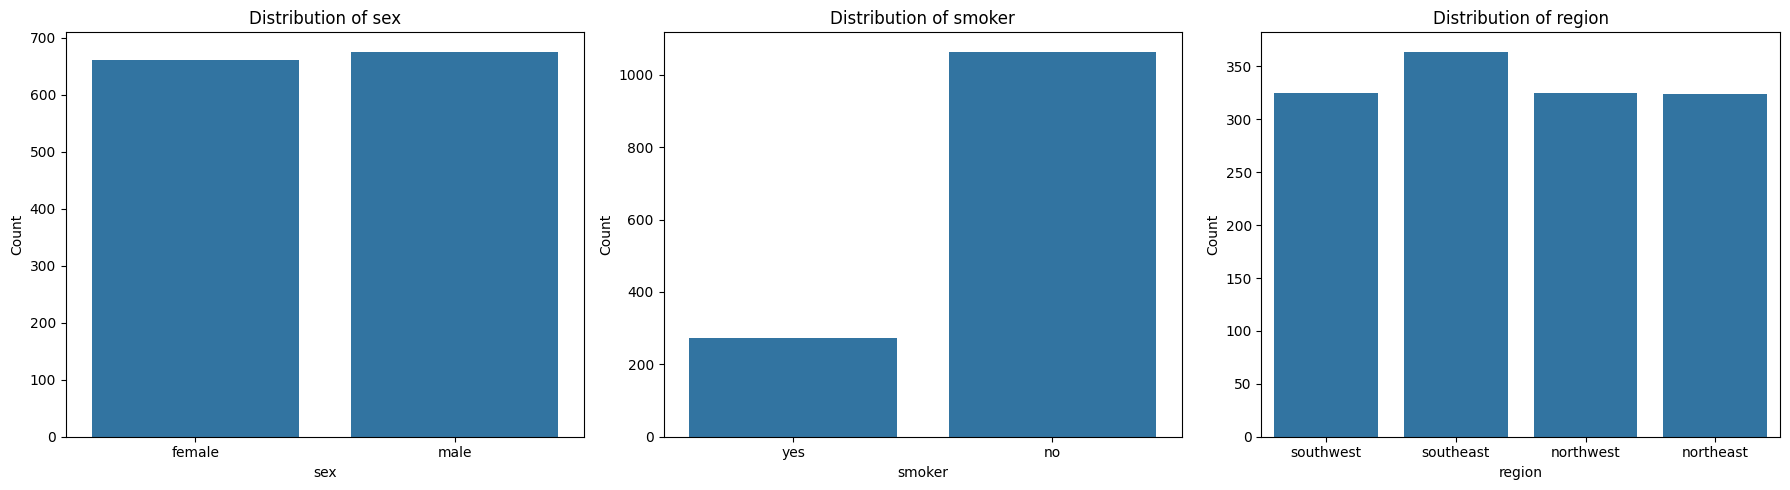

In [7]:
# Step 2: Visualize Data Distributions

# Set up the matplotlib figure
plt.figure(figsize=(15, 10))

# Histograms for continuous variables
for i, col in enumerate(['age', 'bmi', 'children', 'charges'], 1):
    plt.subplot(2, 2, i)
    sns.histplot(insurance_data[col], kde=True)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')

# Show the plots
plt.tight_layout()
plt.show()

# Bar plots for categorical variables
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, feature in zip(axes.flat, ['sex', 'smoker', 'region']):
    sns.countplot(x=feature, data=insurance_data, ax=ax)
    ax.set_title(f'Distribution of {feature}')
    ax.set_xlabel(feature)
    ax.set_ylabel('Count')
plt.tight_layout()
plt.show()

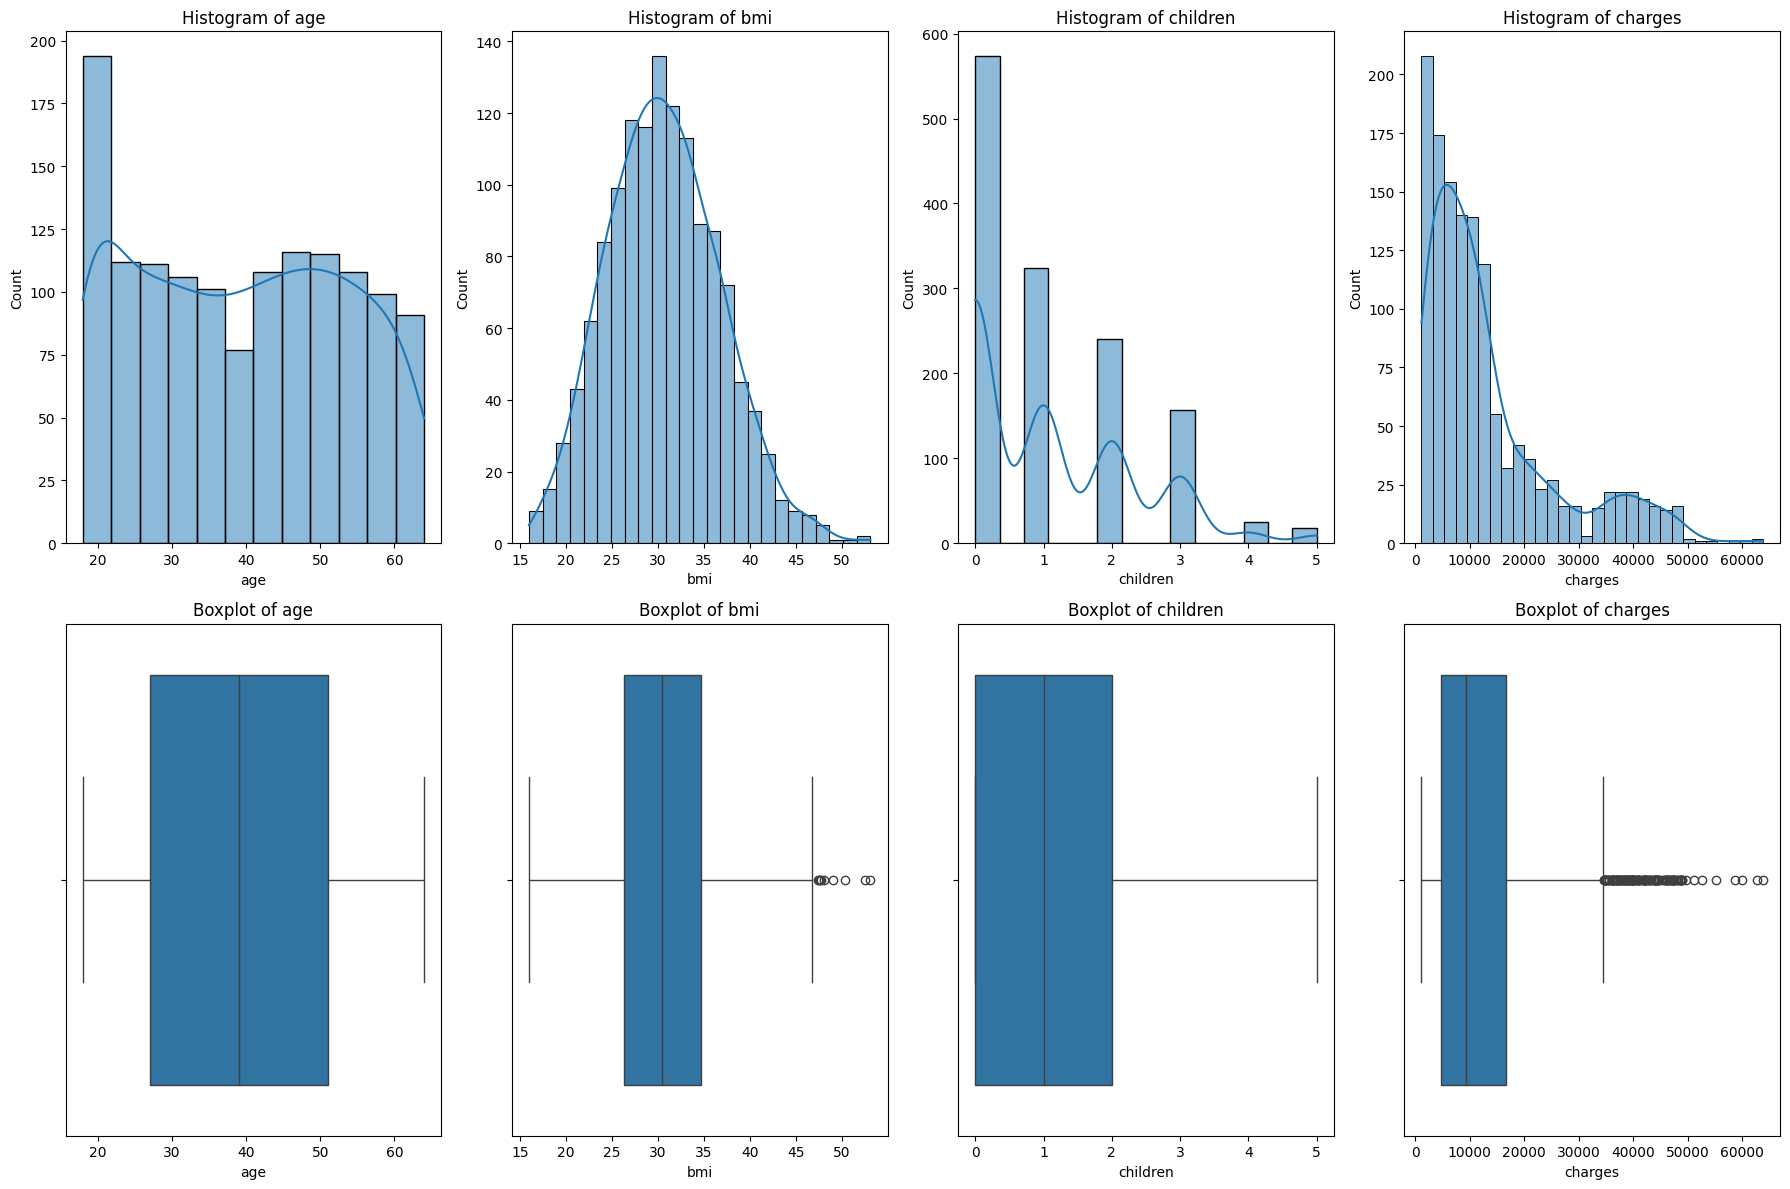

In [8]:
# Visualizing Distributions of Features

# Set up the matplotlib figure for histograms and boxplots
plt.figure(figsize=(18, 12))

# Histograms and boxplots for continuous variables
for i, col in enumerate(['age', 'bmi', 'children', 'charges'], 1):
    plt.subplot(2, 4, i)
    sns.histplot(insurance_data[col], kde=True)
    plt.title(f'Histogram of {col}')

    plt.subplot(2, 4, i + 4)
    sns.boxplot(x=insurance_data[col])
    plt.title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

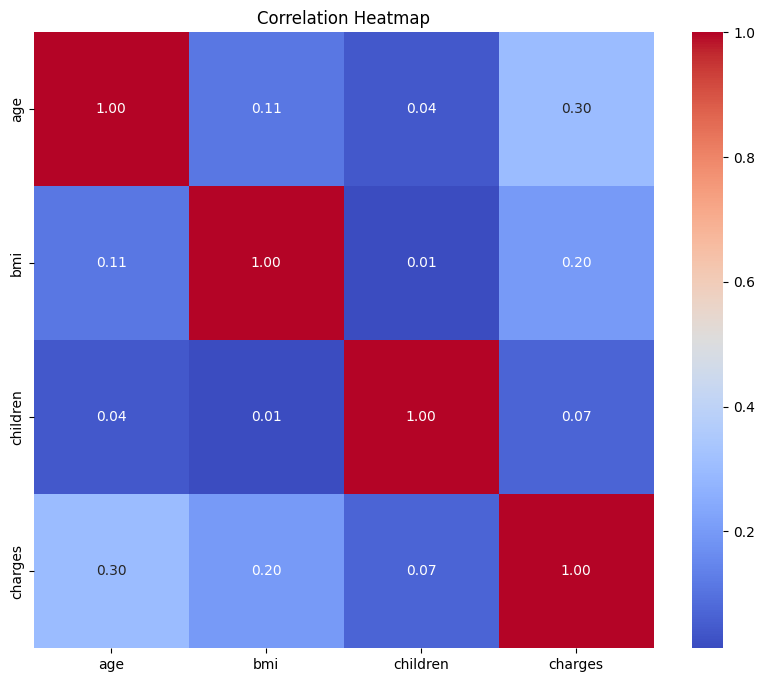

In [9]:
# Examining Correlations Between Features

# Calculate correlation matrix for all variables
correlation_matrix = insurance_data.select_dtypes(include=[np.number]).corr()

# Set up the matplotlib figure for the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title('Correlation Heatmap')
plt.show()

# generate a heatmap to visualize the correlations between all features, including the target variable charges. This helps in understanding how different features may influence the insurance charges.

### Correlation Heatmap Analysis

The heatmap provides the following insights:

- **Age and Charges** : Moderate positive correlation, indicating that charges tend to be higher for older individuals.
- **BMI and Charges** : Slight positive correlation, suggesting that higher BMI might be associated with higher medical costs.
- **Children and Charges** : Weak positive correlation, showing that having more dependents slightly increases charges.

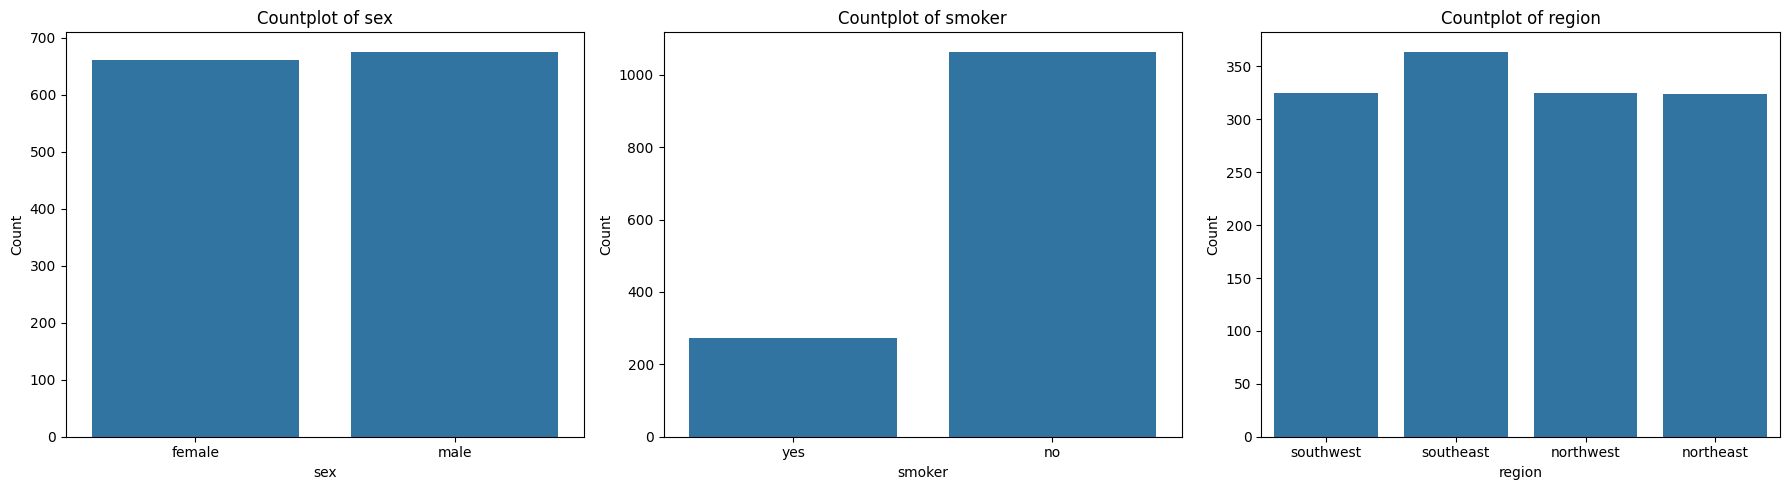

(9, 139)

In [10]:
# Identifying Outliers
# Checking for Data Imbalances

# Identifying outliers using the 1.5*IQR rule for 'bmi' and 'charges'
def detect_outliers(data, feature):
    Q1 = data[feature].quantile(0.25)
    Q3 = data[feature].quantile(0.75)
    IQR = Q3 - Q1
    outlier_thresholds = (Q1 - 1.5 * IQR, Q3 + 1.5 * IQR)
    return data[(data[feature] < outlier_thresholds[0]) | (data[feature] > outlier_thresholds[1])]

outliers_bmi = detect_outliers(insurance_data, 'bmi')
outliers_charges = detect_outliers(insurance_data, 'charges')

# Visualizing imbalances in categorical features
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, feature in zip(axes.flat, ['sex', 'smoker', 'region']):
    sns.countplot(x=feature, data=insurance_data, ax=ax)
    ax.set_title(f'Countplot of {feature}')
    ax.set_xlabel(feature)
    ax.set_ylabel('Count')
plt.tight_layout()
plt.show()

outliers_bmi.shape[0], outliers_charges.shape[0]  # Returning counts of outliers

### Identifying Outliers
I've already looked at boxplots, which highlighted potential outliers, particularly in bmi and charges.

- **BMI** : There are 9 outliers detected. These values are significantly higher or lower than the typical range observed in the dataset.
- **Charges** : There are 139 outliers. These are primarily on the higher end, indicative of unusually high medical charges compared to the general distribution.


### Checking for Data Imbalances

It's also important to check for imbalances in categorical features (sex, smoker, region), as these can influence model training and predictions.


- **Sex** : The distribution between male and female is almost even, indicating no significant imbalance.
- **Smoker** : There are considerably fewer smokers than non-smokers. This imbalance can significantly impact model predictions since smoking status is a strong predictor of medical charges.
- **Region** : Distribution across regions is relatively balanced, with no single region dominating.

### Data Distribution Visualizations

#### Continuous Variables

- **Age** : The age distribution is fairly uniform across different age groups.

- **BMI** : The distribution is approximately normal but slightly right-skewed, suggesting a few outliers with higher BMI.

- **Children** : Most policyholders have fewer than 3 children, with the majority having none.

- **Charges** : The distribution is highly right-skewed, indicating that higher medical charges are less common but significant.

#### Categorical Variables

- **Sex** : The distribution between males and females is almost equal.
  
- **Smoker** : There are significantly fewer smokers compared to non-smokers in the dataset.
  
- **Region** : The distribution across different regions is relatively uniform.


### Insights and Potential Actions

- Outliers in bmi and charges could potentially skew the predictions of a regression model. Depending on the model's sensitivity to outliers, it might be necessary to either remove these points or use robust scaling methods.

- Imbalance in smoker status: Given its potential impact on the target variable charges, special attention should be paid to how this feature is handled during model training, possibly by using stratified sampling or adjusting class weights.

## Exploratory Data Analysis (EDA) Summary

### Distribution Visualizations
- Histograms and boxplots were used to explore the distributions of continuous features (`age`, `bmi`, `children`, `charges`). Notably, `charges` are highly right-skewed, indicating the presence of high-cost outliers.
- Categorical features (`sex`, `smoker`, `region`) were examined for balance. An imbalance was found in `smoker`, with far fewer smokers than non-smokers.

### Correlation Analysis
- A heatmap revealed moderate to weak correlations between features and the target variable `charges`. `Age` shows the strongest correlation, followed by `bmi`.

### Outlier Detection
- Statistical methods identified significant outliers in `bmi` and `charges`. These outliers could influence model performance and may need to be addressed.

### Data Imbalance
- The significant imbalance in the `smoker` feature suggests the need for careful handling during model training to avoid bias.

These insights will inform subsequent model design and feature engineering steps, ensuring a well-informed approach to building the predictive model.

In [11]:
insurance_data['charges_log'] = np.log(insurance_data['charges'] + 1) 

insurance_data['bmi_box_cox'], fitted_lambda = stats.boxcox(insurance_data['bmi'] + 0.1)  # Adding 0.1 to handle zero or negative values

outliers_bmi = detect_outliers(insurance_data, 'bmi_box_cox')
outliers_charges = detect_outliers(insurance_data, 'charges_log')

# Output the number of outliers detected post-transformation
print("Outliers in BMI (Box-Cox):", outliers_bmi.shape[0])
print("Outliers in Charges (Log):", outliers_charges.shape[0])

Outliers in BMI (Box-Cox): 4
Outliers in Charges (Log): 0


## Data Transformation Rationale

### Overview
As part of the preprocessing for predicting health insurance charges, I focus on addressing data distribution and potential outliers in key variables: `bmi` and `charges`. Proper handling of these variables is crucial as they significantly influence model performance and accuracy.

### Reasons for Transforming `bmi` and `charges`

1. **Skewness and Outliers**
   - Both `bmi` and `charges` exhibit skewed distributions. `bmi` is less skewed but has notable outliers, while `charges` is highly skewed towards higher values. Skewed data can mislead the model resulting in poor predictions, especially for regression tasks.
   
2. **Transformation Benefits**
   - Transformations help in stabilizing variance and normalizing data. They reduce the influence of extreme values or outliers, making patterns in the data more interpretable and accessible for modeling.

### Selected Transformation Methods

1. **Box-Cox Transformation for `bmi`**
   - **Choice Justification**: The Box-Cox transformation is chosen for `bmi` as it can handle and correct moderate skewness effectively. This transformation also helps in dealing with outliers by compressing the upper tail of the distribution.
   - **Implementation**: We add a small constant (0.1) to avoid issues with zero or negative values that are not compatible with the logarithmic component of the Box-Cox transformation.

2. **Log Transformation for `charges`**
   - **Choice Justification** : Given the significant right skewness of charges, a log transformation is appropriate. It's particularly effective for reducing the impact of extreme higher values, thus normalizing the distribution substantially.
   - **Implementation** : A log transformation is applied, with an increment by 1 to handle any zero values, ensuring all inputs to the log function are positive.

### Conclusion
These preprocessing steps are vital for reducing potential biases and improving the predictability of the model. By normalizing the key predictors, we enhance the model's ability to learn the underlying patterns without being unduly influenced by anomalies or skewed data.

In [12]:
# Step 0: Split the data into training and test sets
X = insurance_data.drop(['charges', 'charges_log', 'bmi'], axis=1)
y = insurance_data['charges_log']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Define the columns and the transformers for the column transformer
categorical_features = ['sex', 'smoker', 'region']
continuous_features = ['age', 'bmi_box_cox', 'children']

# Create the preprocessing pipelines for both numeric and categorical data
categorical_transformer = OneHotEncoder()
numeric_transformer = StandardScaler()

# Combine all pieces using ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, continuous_features),
        ('cat', categorical_transformer, categorical_features)
    ])

# Fit the preprocessor on the training data and transform both training and test sets
X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

# The resulting array needs to be converted back to a dataframe
columns_transformed = preprocessor.transformers_[1][1].get_feature_names_out(categorical_features)
all_columns = list(continuous_features) + list(columns_transformed)

X_train_df = pd.DataFrame(X_train_transformed, columns=all_columns)
X_test_df = pd.DataFrame(X_test_transformed, columns=all_columns)

# Show the first few rows of the transformed training data
X_train_df.head()

,age,bmi_box_cox,children,sex_female,sex_male,smoker_no,smoker_yes,region_northeast,region_northwest,region_southeast,region_southwest
0,0.472227,-1.899495,0.734336,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
1,0.543313,-1.040043,-0.911192,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
2,0.898745,-0.939826,-0.911192,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
3,-0.025379,0.654730,3.202629,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
4,1.040918,-1.590006,1.557100,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0


## Data Preprocessing Summary

### Step 0: Data Splitting
- The dataset was split into training and test sets to ensure that model validation is performed on unseen data. This helps prevent data leakage during model evaluation.

### Step 1: Encoding and Scaling
- **Encoding Categorical Variables**: Categorical features (`sex`, `smoker`, `region`) were transformed using one-hot encoding, allowing the model to better interpret these as numerical inputs.
- **Scaling Continuous Variables**: Continuous features (`age`, `bmi`, `children`) were scaled using a standard scaler to ensure that they have zero mean and unit variance.

### Implementation Details
- The transformations were defined using `ColumnTransformer` which applies the appropriate transformations to categorical and continuous features respectively.
- Preprocessors were fitted only on the training data (`X_train`) to prevent leakage of information from the test set (`X_test`). After fitting, these preprocessors were used to transform both the training and test sets.

This approach ensures that the model is trained and validated on appropriately preprocessed data without any bias or leakage from the test data.

## Training and Evaluation Helper

Every model is trained full-batch for `EPOCHS` epochs with Adam (learning rate 0.001) and an MSE loss on
the log-transformed target. Because the whole training set is one batch, each epoch is a single optimiser
step; 2,000 epochs are used because with only ~100 steps the networks are still far from the target range
(test R² < 0). Training all six models still takes well under a minute on a CPU.

Targets are reshaped to `(N, 1)` so that they match the network output shape; otherwise
`MSELoss` would silently broadcast `(N, 1)` against `(N,)` into an `N × N` matrix.
After each epoch the helper records the train/test MSE and the coefficient of determination (R²).

In [13]:
def train_and_evaluate(model, criterion, optimizer, X_train, y_train, X_test, y_test, epochs=100, name="model"):
    # Lists to store metrics for plotting
    epoch_count = []
    train_losses, test_losses = [], []
    train_r2_list, test_r2_list = [], []

    inputs = torch.tensor(X_train, dtype=torch.float32)
    targets = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)
    test_inputs = torch.tensor(X_test, dtype=torch.float32)
    test_targets = torch.tensor(y_test, dtype=torch.float32).view(-1, 1)

    def r2(pred, true):
        return 1 - torch.sum((true - pred) ** 2) / torch.sum((true - true.mean()) ** 2)

    for epoch in range(epochs):
        # Training Phase
        model.train()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Evaluation Phase
        model.eval()
        with torch.no_grad():
            train_outputs = model(inputs)
            train_mse = criterion(train_outputs, targets)
            test_outputs = model(test_inputs)
            test_mse = criterion(test_outputs, test_targets)

        # Store metrics for plotting
        epoch_count.append(epoch + 1)
        train_losses.append(train_mse.item())
        test_losses.append(test_mse.item())
        train_r2_list.append(r2(train_outputs, targets).item())
        test_r2_list.append(r2(test_outputs, test_targets).item())

        if (epoch + 1) % (epochs // 10) == 0 or epoch == 0:
            print(f'Epoch {epoch+1}/{epochs}, Loss: {loss.item():.4f}, Train MSE: {train_mse.item():.4f}, '
                  f'Test MSE: {test_mse.item():.4f}, Test R2: {test_r2_list[-1]:.4f}')

    # Plotting
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    axes[0].plot(epoch_count, train_losses, label='Train MSE')
    axes[0].plot(epoch_count, test_losses, label='Test MSE')
    axes[0].set_yscale('log')
    axes[0].set_title(f'{name}: MSE over Epochs')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('MSE (log scale)')
    axes[0].legend()

    axes[1].plot(epoch_count, train_r2_list, label='Train R²')
    axes[1].plot(epoch_count, test_r2_list, label='Test R²')
    axes[1].set_ylim(-1, 1)
    axes[1].set_title(f'{name}: R² over Epochs')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('R²')
    axes[1].legend()

    plt.tight_layout()
    plt.show()

    return {
        "train_mse": train_losses[-1],
        "test_mse": test_losses[-1],
        "train_r2": train_r2_list[-1],
        "test_r2": test_r2_list[-1],
    }


results = {}

In [14]:
class SimpleMLP1(nn.Module):
    def __init__(self, input_features):
        super(SimpleMLP1, self).__init__()
        self.fc1 = nn.Linear(input_features, 12)
        self.fc3 = nn.Linear(12, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.sigmoid(self.fc1(x))
        x = self.fc3(x)
        return x

Epoch 1/2000, Loss: 78.7889, Train MSE: 78.6395, Test MSE: 77.5154, Test R2: -85.2381
Epoch 200/2000, Loss: 50.0586, Train MSE: 49.9143, Test MSE: 49.0286, Test R2: -53.5457


Epoch 400/2000, Loss: 24.6620, Train MSE: 24.5594, Test MSE: 23.9527, Test R2: -25.6481
Epoch 600/2000, Loss: 9.3568, Train MSE: 9.3048, Test MSE: 8.9615, Test R2: -8.9700


Epoch 800/2000, Loss: 2.7484, Train MSE: 2.7310, Test MSE: 2.5789, Test R2: -1.8691
Epoch 1000/2000, Loss: 0.9312, Train MSE: 0.9276, Test MSE: 0.8710, Test R2: 0.0310


Epoch 1200/2000, Loss: 0.5845, Train MSE: 0.5838, Test MSE: 0.5549, Test R2: 0.3826
Epoch 1400/2000, Loss: 0.4998, Train MSE: 0.4995, Test MSE: 0.4738, Test R2: 0.4729


Epoch 1600/2000, Loss: 0.4495, Train MSE: 0.4493, Test MSE: 0.4246, Test R2: 0.5277
Epoch 1800/2000, Loss: 0.4047, Train MSE: 0.4044, Test MSE: 0.3824, Test R2: 0.5746


Epoch 2000/2000, Loss: 0.3627, Train MSE: 0.3625, Test MSE: 0.3428, Test R2: 0.6187


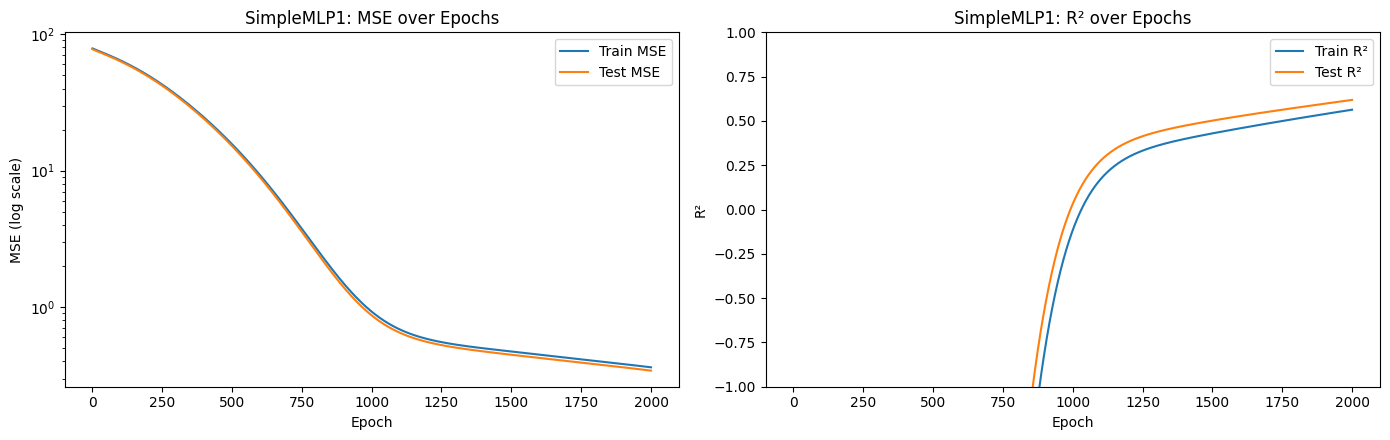

In [15]:
# Setup the model, criterion, and optimizer
set_seed()
model = SimpleMLP1(input_features=X_train_df.shape[1])
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

# Training and evaluation
results["SimpleMLP1"] = train_and_evaluate(model, criterion, optimizer, X_train_df.values, y_train.values,
                                       X_test_df.values, y_test.values, epochs=EPOCHS, name="SimpleMLP1")

In [16]:
class SimpleMLP2(nn.Module):
    def __init__(self, input_features):
        super(SimpleMLP2, self).__init__()
        self.fc1 = nn.Linear(input_features, 32)
        self.fc3 = nn.Linear(32, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.sigmoid(self.fc1(x))
        x = self.fc3(x)
        return x

Epoch 1/2000, Loss: 86.9203, Train MSE: 86.5679, Test MSE: 85.3394, Test R2: -93.9425
Epoch 200/2000, Loss: 28.7606, Train MSE: 28.5220, Test MSE: 27.8715, Test R2: -30.0079


Epoch 400/2000, Loss: 2.8163, Train MSE: 2.7788, Test MSE: 2.6186, Test R2: -1.9133
Epoch 600/2000, Loss: 0.5647, Train MSE: 0.5634, Test MSE: 0.5294, Test R2: 0.4110


Epoch 800/2000, Loss: 0.4456, Train MSE: 0.4452, Test MSE: 0.4207, Test R2: 0.5319
Epoch 1000/2000, Loss: 0.3708, Train MSE: 0.3705, Test MSE: 0.3485, Test R2: 0.6123


Epoch 1200/2000, Loss: 0.3094, Train MSE: 0.3092, Test MSE: 0.2890, Test R2: 0.6785
Epoch 1400/2000, Loss: 0.2606, Train MSE: 0.2604, Test MSE: 0.2411, Test R2: 0.7317


Epoch 1600/2000, Loss: 0.2234, Train MSE: 0.2233, Test MSE: 0.2044, Test R2: 0.7726
Epoch 1800/2000, Loss: 0.1968, Train MSE: 0.1967, Test MSE: 0.1779, Test R2: 0.8021


Epoch 2000/2000, Loss: 0.1790, Train MSE: 0.1789, Test MSE: 0.1601, Test R2: 0.8219


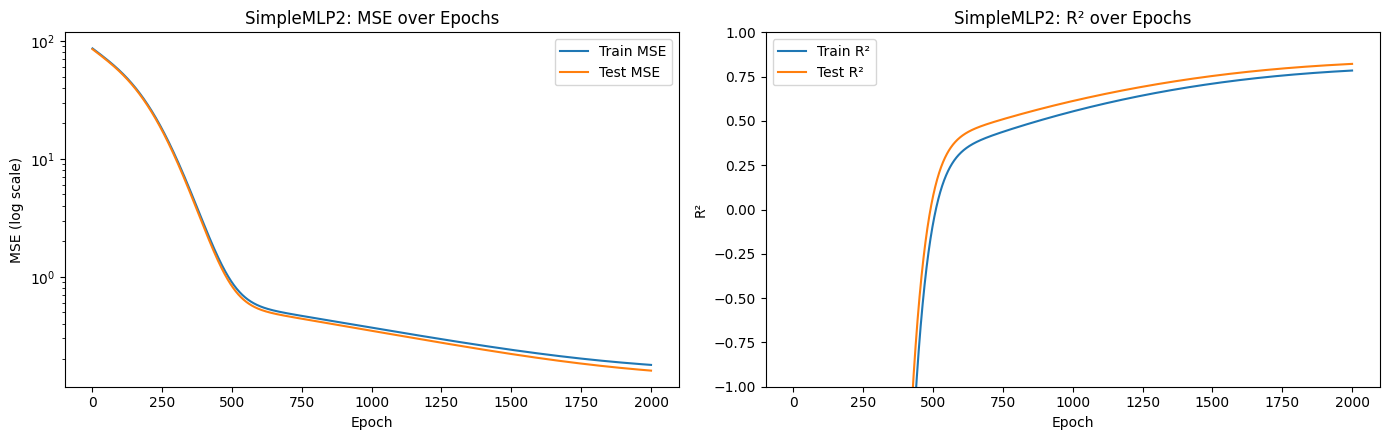

In [17]:
# Setup the model, criterion, and optimizer
set_seed()
model = SimpleMLP2(input_features=X_train_df.shape[1])
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

# Training and evaluation
results["SimpleMLP2"] = train_and_evaluate(model, criterion, optimizer, X_train_df.values, y_train.values,
                                       X_test_df.values, y_test.values, epochs=EPOCHS, name="SimpleMLP2")

In [18]:
class SimpleMLP3(nn.Module):
    def __init__(self, input_features):
        super(SimpleMLP3, self).__init__()
        self.fc1 = nn.Linear(input_features, 64)
        self.fc3 = nn.Linear(64, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.sigmoid(self.fc1(x))
        x = self.fc3(x)
        return x

Epoch 1/2000, Loss: 84.8260, Train MSE: 84.1636, Test MSE: 82.8672, Test R2: -91.1921


Epoch 200/2000, Loss: 5.7605, Train MSE: 5.6364, Test MSE: 5.3944, Test R2: -5.0015


Epoch 400/2000, Loss: 0.4864, Train MSE: 0.4857, Test MSE: 0.4590, Test R2: 0.4894


Epoch 600/2000, Loss: 0.3662, Train MSE: 0.3657, Test MSE: 0.3422, Test R2: 0.6193


Epoch 800/2000, Loss: 0.2812, Train MSE: 0.2808, Test MSE: 0.2577, Test R2: 0.7133


Epoch 1000/2000, Loss: 0.2267, Train MSE: 0.2265, Test MSE: 0.2040, Test R2: 0.7731


Epoch 1200/2000, Loss: 0.1955, Train MSE: 0.1954, Test MSE: 0.1736, Test R2: 0.8069


Epoch 1400/2000, Loss: 0.1794, Train MSE: 0.1794, Test MSE: 0.1582, Test R2: 0.8240


Epoch 1600/2000, Loss: 0.1716, Train MSE: 0.1716, Test MSE: 0.1510, Test R2: 0.8320


Epoch 1800/2000, Loss: 0.1676, Train MSE: 0.1676, Test MSE: 0.1476, Test R2: 0.8358


Epoch 2000/2000, Loss: 0.1652, Train MSE: 0.1652, Test MSE: 0.1457, Test R2: 0.8380


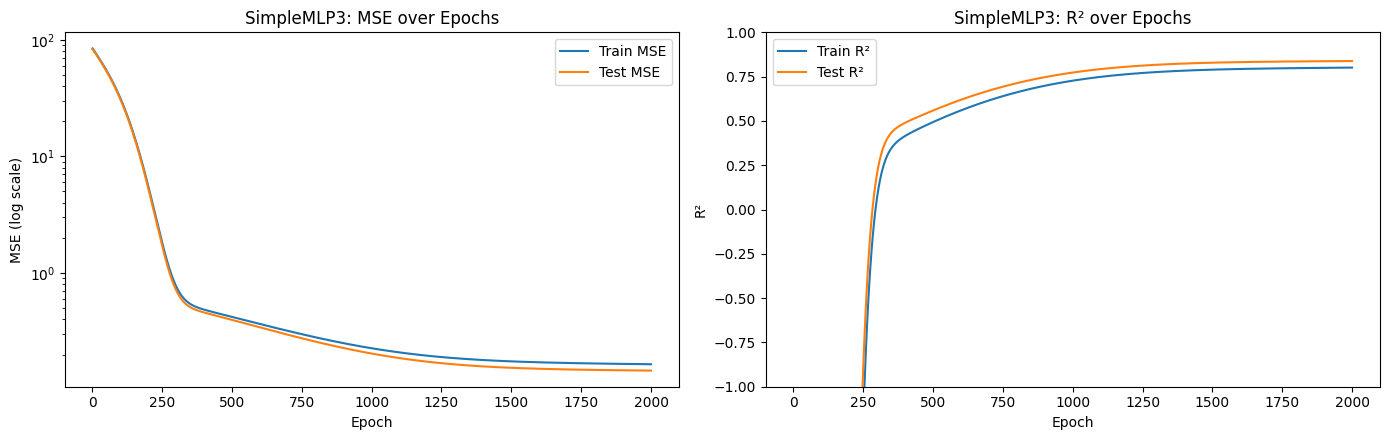

In [19]:
# Setup the model, criterion, and optimizer
set_seed()
model = SimpleMLP3(input_features=X_train_df.shape[1])
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

# Training and evaluation
results["SimpleMLP3"] = train_and_evaluate(model, criterion, optimizer, X_train_df.values, y_train.values,
                                       X_test_df.values, y_test.values, epochs=EPOCHS, name="SimpleMLP3")

In [20]:
class SimpleMLP4(nn.Module):
    def __init__(self, input_features):
        super(SimpleMLP4, self).__init__()
        self.fc1 = nn.Linear(input_features, 64)
        self.fc3 = nn.Linear(64, 1)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.fc3(x)
        return x

Epoch 1/2000, Loss: 86.2927, Train MSE: 85.9135, Test MSE: 84.7204, Test R2: -93.2539


Epoch 200/2000, Loss: 0.8644, Train MSE: 0.8467, Test MSE: 0.8108, Test R2: 0.0980


Epoch 400/2000, Loss: 0.3746, Train MSE: 0.3738, Test MSE: 0.3630, Test R2: 0.5961


Epoch 600/2000, Loss: 0.2845, Train MSE: 0.2843, Test MSE: 0.2773, Test R2: 0.6915


Epoch 800/2000, Loss: 0.2470, Train MSE: 0.2468, Test MSE: 0.2401, Test R2: 0.7329


Epoch 1000/2000, Loss: 0.2252, Train MSE: 0.2251, Test MSE: 0.2177, Test R2: 0.7578


Epoch 1200/2000, Loss: 0.2110, Train MSE: 0.2109, Test MSE: 0.2029, Test R2: 0.7743


Epoch 1400/2000, Loss: 0.1952, Train MSE: 0.1951, Test MSE: 0.1862, Test R2: 0.7928


Epoch 1600/2000, Loss: 0.1660, Train MSE: 0.1658, Test MSE: 0.1580, Test R2: 0.8242


Epoch 1800/2000, Loss: 0.1464, Train MSE: 0.1463, Test MSE: 0.1368, Test R2: 0.8478


Epoch 2000/2000, Loss: 0.1378, Train MSE: 0.1378, Test MSE: 0.1297, Test R2: 0.8557


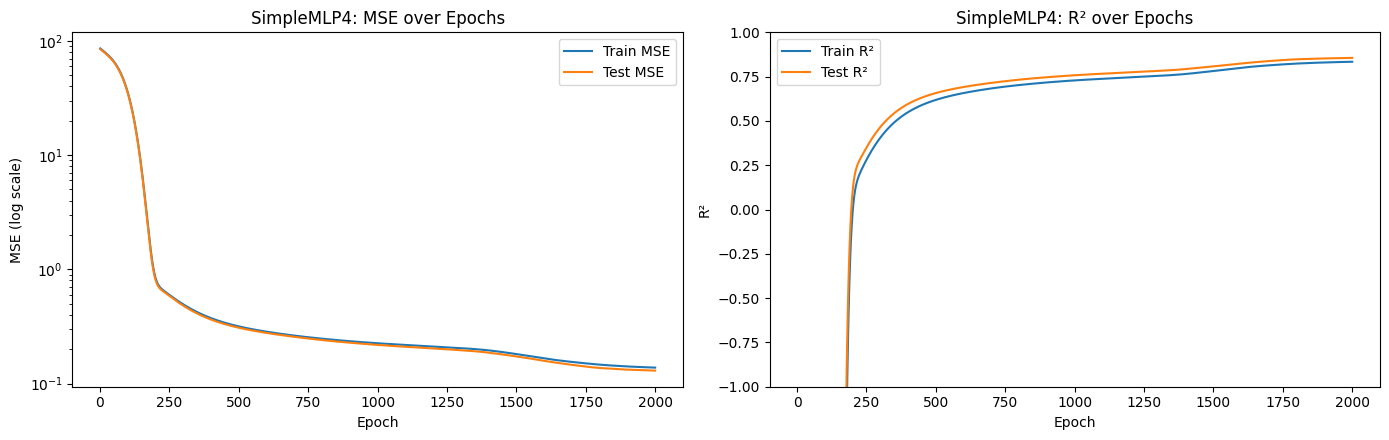

In [21]:
# Setup the model, criterion, and optimizer
set_seed()
model = SimpleMLP4(input_features=X_train_df.shape[1])
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

# Training and evaluation
results["SimpleMLP4"] = train_and_evaluate(model, criterion, optimizer, X_train_df.values, y_train.values,
                                       X_test_df.values, y_test.values, epochs=EPOCHS, name="SimpleMLP4")

In [22]:
class SimpleMLP5(nn.Module):
    def __init__(self, input_features):
        super(SimpleMLP5, self).__init__()
        self.fc1 = nn.Linear(input_features, 64)
        self.fc2 = nn.Linear(64, 64)
        self.fc3 = nn.Linear(64, 1)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return x

Epoch 1/2000, Loss: 82.8467, Train MSE: 82.2443, Test MSE: 81.0189, Test R2: -89.1358


Epoch 200/2000, Loss: 0.5987, Train MSE: 0.5958, Test MSE: 0.6380, Test R2: 0.2902


Epoch 400/2000, Loss: 0.2952, Train MSE: 0.2944, Test MSE: 0.2964, Test R2: 0.6702


Epoch 600/2000, Loss: 0.1931, Train MSE: 0.1928, Test MSE: 0.1805, Test R2: 0.7992


Epoch 800/2000, Loss: 0.1592, Train MSE: 0.1591, Test MSE: 0.1440, Test R2: 0.8398


Epoch 1000/2000, Loss: 0.1446, Train MSE: 0.1445, Test MSE: 0.1326, Test R2: 0.8525


Epoch 1200/2000, Loss: 0.1371, Train MSE: 0.1370, Test MSE: 0.1284, Test R2: 0.8571


Epoch 1400/2000, Loss: 0.1331, Train MSE: 0.1331, Test MSE: 0.1274, Test R2: 0.8583


Epoch 1600/2000, Loss: 0.1302, Train MSE: 0.1302, Test MSE: 0.1272, Test R2: 0.8585


Epoch 1800/2000, Loss: 0.1280, Train MSE: 0.1280, Test MSE: 0.1271, Test R2: 0.8586


Epoch 2000/2000, Loss: 0.1262, Train MSE: 0.1262, Test MSE: 0.1271, Test R2: 0.8586


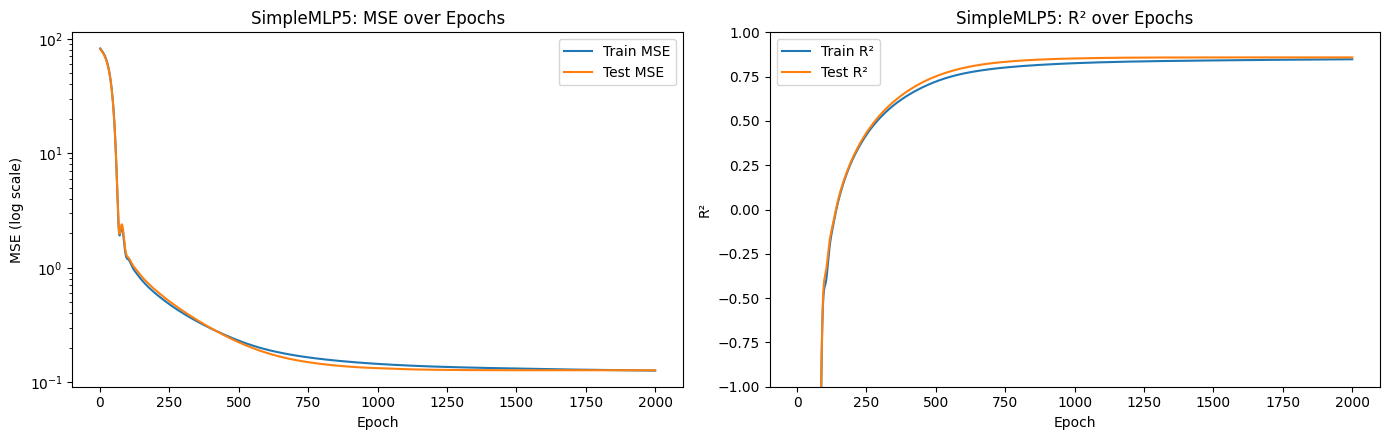

In [23]:
# Setup the model, criterion, and optimizer
set_seed()
model = SimpleMLP5(input_features=X_train_df.shape[1])
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

# Training and evaluation
results["SimpleMLP5"] = train_and_evaluate(model, criterion, optimizer, X_train_df.values, y_train.values,
                                       X_test_df.values, y_test.values, epochs=EPOCHS, name="SimpleMLP5")

## Network Architectures 1–5

The first five networks isolate the effect of **width**, **activation function** and **depth**:

| Model | Hidden layers | Activation |
|---|---|---|
| SimpleMLP1 | 12 | Sigmoid |
| SimpleMLP2 | 32 | Sigmoid |
| SimpleMLP3 | 64 | Sigmoid |
| SimpleMLP4 | 64 | ReLU |
| SimpleMLP5 | 64 → 64 | ReLU |

All models end in a single linear output neuron because this is a regression task.

### Why these architectures?

- **Width (12 → 32 → 64 neurons)**: more hidden units give the network more capacity to model interactions
  such as smoker × BMI, while 64 units are still small enough for a 1,070-row training set.
- **Sigmoid vs. ReLU**: ReLU avoids the saturating gradients of the sigmoid, which usually speeds up training.
- **Second hidden layer**: lets the network combine features hierarchically.

## Hyperparameters

- **Learning rate 0.001** with **Adam**: a robust default for small dense networks.
- **Loss: MSE** on `log(charges + 1)`.
- **2,000 full-batch epochs** (2,000 optimiser steps); see the training-helper section for why.

## Training Process and Results

- **Width helps.** With sigmoid activations, test R² rises from about 0.62 (12 units) to 0.82 (32 units) and
  0.84 (64 units). The 12-unit network is still improving at epoch 2,000; it learns more slowly rather than
  hitting a hard capacity limit.
- **ReLU converges faster** than sigmoid at the same width (SimpleMLP4 vs. SimpleMLP3) and ends with a
  slightly better test R² (≈ 0.856 vs. ≈ 0.838).
- **Depth gives the best model.** SimpleMLP5 (two ReLU layers) reaches the lowest test MSE and the highest
  test R² (≈ 0.859).
- **No overfitting.** Train and test curves track each other closely for every model. The test R² is even
  slightly higher than the train R², which reflects this particular 80/20 split rather than a modelling issue.

The exact numbers for every model are in the *Model Comparison* table below.

In [24]:
class EnhancedMLP(nn.Module):
    def __init__(self, input_features):
        super(EnhancedMLP, self).__init__()
        self.fc1 = nn.Linear(input_features, 64)
        self.relu1 = nn.ReLU()
        self.dropout1 = nn.Dropout(0.5)  # Dropout layer
        self.fc2 = nn.Linear(64, 64)
        self.relu2 = nn.ReLU()
        self.dropout2 = nn.Dropout(0.3)
        self.fc3 = nn.Linear(64, 64)
        self.relu3 = nn.ReLU()
        self.dropout3 = nn.Dropout(0.1)
        self.fc4 = nn.Linear(64, 1)

    def forward(self, x):
        x = self.dropout1(self.relu1(self.fc1(x)))
        x = self.dropout2(self.relu2(self.fc2(x)))
        x = self.dropout3(self.relu3(self.fc3(x)))
        x = self.fc4(x)
        return x

Epoch 1/2000, Loss: 86.1082, Train MSE: 85.5678, Test MSE: 84.3137, Test R2: -92.8014


Epoch 200/2000, Loss: 3.4446, Train MSE: 0.7029, Test MSE: 0.6762, Test R2: 0.2477


Epoch 400/2000, Loss: 2.0247, Train MSE: 0.7274, Test MSE: 0.6853, Test R2: 0.2376


Epoch 600/2000, Loss: 1.3139, Train MSE: 0.5528, Test MSE: 0.5093, Test R2: 0.4334


Epoch 800/2000, Loss: 1.2180, Train MSE: 0.3269, Test MSE: 0.2976, Test R2: 0.6690


Epoch 1000/2000, Loss: 1.1281, Train MSE: 0.2260, Test MSE: 0.1999, Test R2: 0.7776


Epoch 1200/2000, Loss: 0.9558, Train MSE: 0.1834, Test MSE: 0.1605, Test R2: 0.8214


Epoch 1400/2000, Loss: 0.8290, Train MSE: 0.1692, Test MSE: 0.1490, Test R2: 0.8342


Epoch 1600/2000, Loss: 0.8347, Train MSE: 0.1665, Test MSE: 0.1444, Test R2: 0.8394


Epoch 1800/2000, Loss: 0.7424, Train MSE: 0.1589, Test MSE: 0.1397, Test R2: 0.8446


Epoch 2000/2000, Loss: 0.6606, Train MSE: 0.1656, Test MSE: 0.1430, Test R2: 0.8410


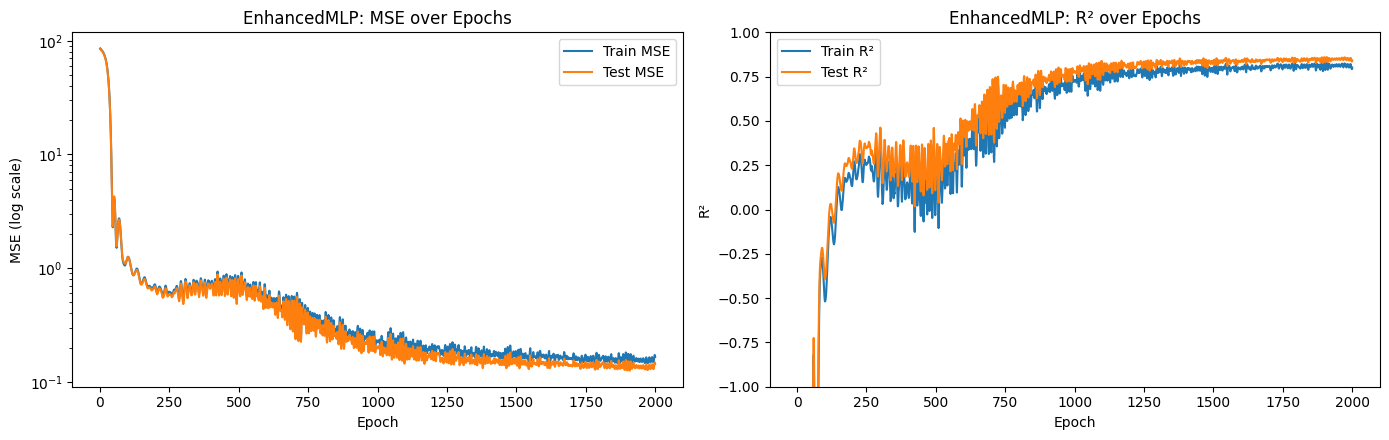

In [25]:
# Setup the model, criterion, and optimizer
set_seed()
model = EnhancedMLP(input_features=X_train_df.shape[1])
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

# Training and evaluation
results["EnhancedMLP"] = train_and_evaluate(model, criterion, optimizer, X_train_df.values, y_train.values,
                                       X_test_df.values, y_test.values, epochs=EPOCHS, name="EnhancedMLP")

## Network Architecture 2: EnhancedMLP

### Layers and Neurons
- **Input layer**: one neuron per feature (11 after one-hot encoding).
- **Hidden layers**: three fully connected layers of 64 neurons each.
- **Output layer**: a single linear neuron that predicts `log(charges + 1)`.

### Activation Functions
- **ReLU** in every hidden layer, which gives non-linearity without the vanishing gradients of
  sigmoid/tanh units.

## Dropout
- Dropout rates of **0.5, 0.3 and 0.1** after the three hidden layers randomly deactivate neurons during
  training. This discourages co-adaptation of neurons and acts as a regulariser for the deeper network.

## Optimiser and Learning Rate
- **Adam** with the same learning rate (0.001) and the same 2,000 full-batch epochs as the other models, so
  the comparison is fair.

## Loss Function
- **Mean Squared Error (MSE)** on the log target. Large errors are penalised more than small ones.

## Training Dynamics and Results Analysis

- Dropout makes the training curves visibly **noisier**, and there is a plateau between roughly epochs 250
  and 600 before the loss drops again. The network still converges to a test R² of about 0.84.
- EnhancedMLP generalises well (no train/test gap). It does **not** beat the simpler two-layer
  SimpleMLP5, however. With only 11 input features and no sign of overfitting in the smaller networks,
  heavy dropout mainly slows learning rather than improving generalisation.
- The dollar-scale evaluation below shows that most of the remaining error comes from a group of
  high-charge policyholders (roughly USD 20k–50k) whose charges the model underestimates.

## Model Comparison

Final-epoch metrics of all six architectures on the log-transformed target.

In [26]:
comparison = pd.DataFrame(results).T[["train_mse", "test_mse", "train_r2", "test_r2"]]
comparison.index.name = "model"
comparison.round(4)

,train_mse,test_mse,train_r2,test_r2
model,,,,
SimpleMLP1,0.3625,0.3428,0.5633,0.6187
SimpleMLP2,0.1789,0.1601,0.7844,0.8219
SimpleMLP3,0.1652,0.1457,0.8010,0.8380
SimpleMLP4,0.1378,0.1297,0.8340,0.8557
SimpleMLP5,0.1262,0.1271,0.8479,0.8586
EnhancedMLP,0.1656,0.1430,0.8004,0.8410


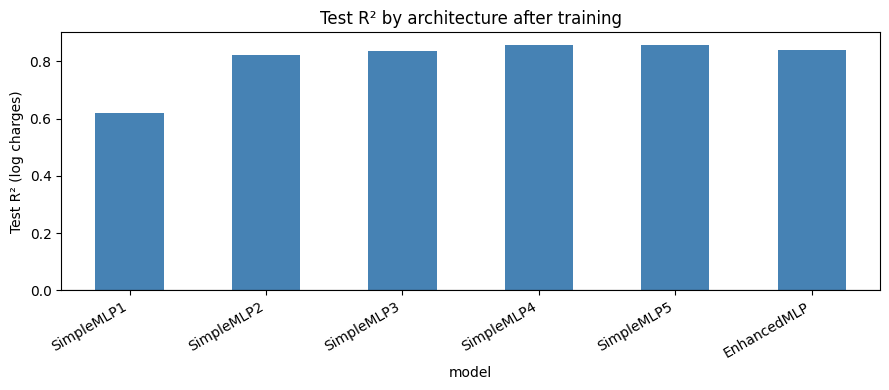

In [27]:
fig, ax = plt.subplots(figsize=(9, 4))
comparison["test_r2"].plot.bar(ax=ax, color="steelblue")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Test R² (log charges)")
ax.set_title("Test R² by architecture after training")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## Evaluation in Dollars

The networks are trained on `log(charges + 1)`. To interpret the final model, its test-set predictions are
mapped back to dollars with `exp(x) - 1` and compared with the true charges.

In [28]:
model.eval()
with torch.no_grad():
    log_pred = model(torch.tensor(X_test_df.values, dtype=torch.float32)).squeeze(1).numpy()

y_true_usd = np.expm1(y_test.values)
y_pred_usd = np.expm1(log_pred)

dollar_metrics = {
    "MAE_usd": float(mean_absolute_error(y_true_usd, y_pred_usd)),
    "RMSE_usd": float(np.sqrt(mean_squared_error(y_true_usd, y_pred_usd))),
    "R2_usd": float(r2_score(y_true_usd, y_pred_usd)),
    "R2_log": float(r2_score(y_test.values, log_pred)),
}
for k, v in dollar_metrics.items():
    print(f"{k:>9}: {v:,.4f}")

  MAE_usd: 3,078.4762
 RMSE_usd: 6,209.9162
   R2_usd: 0.7516
   R2_log: 0.8410


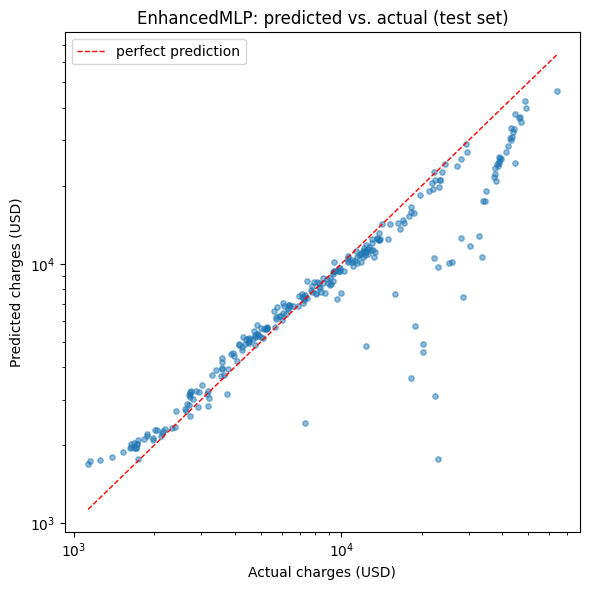

In [29]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_true_usd, y_pred_usd, alpha=0.5, s=15)
lims = [min(y_true_usd.min(), y_pred_usd.min()), max(y_true_usd.max(), y_pred_usd.max())]
ax.plot(lims, lims, "r--", linewidth=1, label="perfect prediction")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Actual charges (USD)")
ax.set_ylabel("Predicted charges (USD)")
ax.set_title("EnhancedMLP: predicted vs. actual (test set)")
ax.legend()
plt.tight_layout()
plt.show()

In [30]:
summary = {
    "seed": SEED,
    "epochs": EPOCHS,
    "learning_rate": LEARNING_RATE,
    "n_train": int(len(X_train_df)),
    "n_test": int(len(X_test_df)),
    "log_target_metrics": {k: {m: round(float(v), 6) for m, v in r.items()} for k, r in results.items()},
    "enhanced_mlp_dollar_metrics": {k: round(v, 4) for k, v in dollar_metrics.items()},
}
(OUTPUT_DIR / "metrics.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))

{
  "seed": 42,
  "epochs": 2000,
  "learning_rate": 0.001,
  "n_train": 1070,
  "n_test": 268,
  "log_target_metrics": {
    "SimpleMLP1": {
      "train_mse": 0.362475,
      "test_mse": 0.342764,
      "train_r2": 0.563268,
      "test_r2": 0.618665
    },
    "SimpleMLP2": {
      "train_mse": 0.178949,
      "test_mse": 0.160062,
      "train_r2": 0.784391,
      "test_r2": 0.821926
    },
    "SimpleMLP3": {
      "train_mse": 0.165176,
      "test_mse": 0.145653,
      "train_r2": 0.800986,
      "test_r2": 0.837957
    },
    "SimpleMLP4": {
      "train_mse": 0.137791,
      "test_mse": 0.129683,
      "train_r2": 0.833981,
      "test_r2": 0.855724
    },
    "SimpleMLP5": {
      "train_mse": 0.126236,
      "test_mse": 0.127122,
      "train_r2": 0.847903,
      "test_r2": 0.858573
    },
    "EnhancedMLP": {
      "train_mse": 0.165644,
      "test_mse": 0.142952,
      "train_r2": 0.800421,
      "test_r2": 0.840962
    }
  },
  "enhanced_mlp_dollar_metrics": {
    "MAE_u

## Saving the Trained Model

In [31]:
def save_model(model, filename):
    filename.parent.mkdir(parents=True, exist_ok=True)
    torch.save(model.state_dict(), filename)
    print(f'Model saved to {filename}')

save_model(model, OUTPUT_DIR / "models" / "enhanced_mlp.pth")

Model saved to ../outputs/models/enhanced_mlp.pth
